# 02 — Modelling: features, split, baselines and models

This notebook explains **how** the models were built. The heavy lifting (CV tuning of 5 models, about 8 minutes) runs in `python -m src.train`; here we load its outputs and recompute the key numbers live so they can be checked.

Run order: `python -m src.run_all` (or `src.features` → `src.train`) first.

In [1]:
import json, sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # so `src` imports work from notebooks/

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from src.config import FEATURE_FILE, FIGURES, MODELS, TABLES, SEED, POOR_THRESHOLD
from src.features import FEATURES, NEXT_WEATHER_FEATURES, NUMERIC_FEATURES

np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160, "display.max_columns", 30)
mae = lambda a, b: float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
feats = pd.read_csv(FEATURE_FILE, parse_dates=["Date", "target_date"])
print(feats.shape)

(24816, 48)


## 1. What one row means

One row = (city, day *t*). Features are known at the end of day *t*; the target `y` is the **observed** PM2.5 on day *t*+1. The check below confirms, for every row, that `y` really is the next day's value in the same city (the calendar is complete, so shifting by one row is shifting by one day).

In [2]:
nxt = feats.set_index(["City", "Date"])["pm_t"]
key = list(zip(feats.City, feats.target_date))
match = nxt.reindex(key).to_numpy()
ok = np.isclose(match, feats.y.to_numpy()) | np.isnan(match)  # NaN: tomorrow's pm_t row dropped (no target for t+1)
print(f"target == next day's PM2.5 for {ok.mean():.1%} of rows")
print(f"{len(FEATURES)} features:")
groups = {
    "PM2.5 history": [c for c in FEATURES if c.startswith("pm_") or c == "city_mean_past"],
    "other pollutants (day t)": ["NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene"],
    "weather (day t)": [c for c in FEATURES if c.endswith("_t") and not c.startswith("pm_")],
    "calendar of target day": ["dow", "month", "doy_sin", "doy_cos", "season", "diwali"],
}
for g, cols in groups.items():
    print(f"  {g:26s} {cols}")
print("oracle-only (ablation):", NEXT_WEATHER_FEATURES)

target == next day's PM2.5 for 100.0% of rows
34 features:
  PM2.5 history              ['pm_t', 'pm_t_was_missing', 'pm_lag1', 'pm_lag2', 'pm_lag6', 'pm_roll3', 'pm_roll7', 'pm_roll30', 'pm_roll7_std', 'pm_diff1', 'city_mean_past']
  other pollutants (day t)   ['NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
  weather (day t)            ['temp_mean_t', 'temp_range_t', 'precip_mm_t', 'wind_mean_t', 'wind_max_t', 'wind_dir_t', 'humidity_t', 'pressure_kpa_t']
  calendar of target day     ['dow', 'month', 'doy_sin', 'doy_cos', 'season', 'diwali']
oracle-only (ablation): ['temp_mean_next', 'temp_range_next', 'precip_mm_next', 'wind_mean_next', 'wind_max_next', 'wind_dir_next', 'humidity_next', 'pressure_kpa_next']


**Note:** `y` matches the next day's observed value wherever that day exists in the feature table. Tomorrow's weather (`*_next`) is **not** in `FEATURES`; it is used only for the "perfect weather forecast" ablation.

## 2. Time-based split

The split is on the year of the **target** day. Shuffling is never used: with lag-1 autocorrelation ≈ 0.87, a random split would put almost-identical neighbouring days in train and test and inflate every score.

In [3]:
summary = feats.groupby("split").agg(
    rows=("y", "size"), cities=("City", "nunique"),
    first=("target_date", "min"), last=("target_date", "max"),
    mean_pm25=("y", "mean"), poor_share=("y_poor", "mean"),
).loc[["train", "val", "test"]].round(3)
summary

,rows,cities,first,last,mean_pm25,poor_share
split,,,,,,
train,13237,17,2015-01-02,2018-12-31,79.294,0.271
val,7115,23,2019-01-01,2019-12-31,58.889,0.169
test,4464,26,2020-01-01,2020-07-01,43.810,0.086


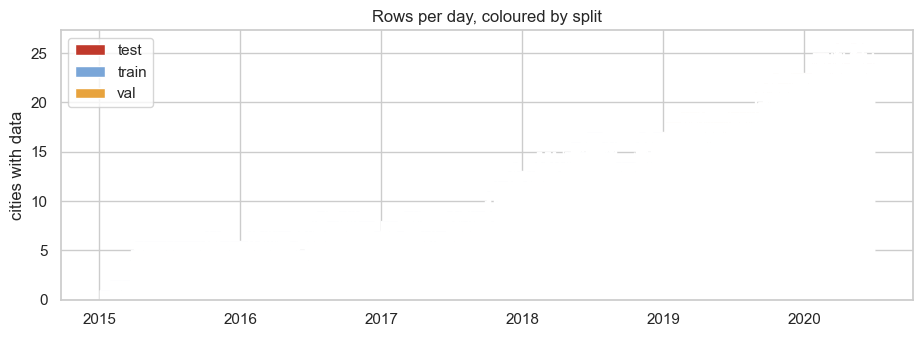

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.5))
colors = {"train": "#7aa6d8", "val": "#e8a33d", "test": "#c0392b"}
for s, g in feats.groupby("split"):
    d = g.groupby("target_date").size()
    ax.bar(d.index, d.values, width=1, color=colors[s], label=s)
ax.set_ylabel("cities with data"); ax.set_title("Rows per day, coloured by split"); ax.legend()
plt.show()

**Insight:** the number of reporting cities grows from ~6 in 2015 to 26 in 2020, and the Poor+ share falls from 27% (train) to 17% (val) and 9% (test). The test year is cleaner, has more cities, and includes the COVID lockdown, so it is a harder, more realistic test than a random split. Nine cities appear only in val/test, which is why no city ID is used as a feature.

## 3. Cross-validation that respects time

Hyperparameters are tuned with 5 **expanding-window** folds inside the training years. Folds are cut on dates, so all cities on one day stay together and every validation fold is later than its training data.

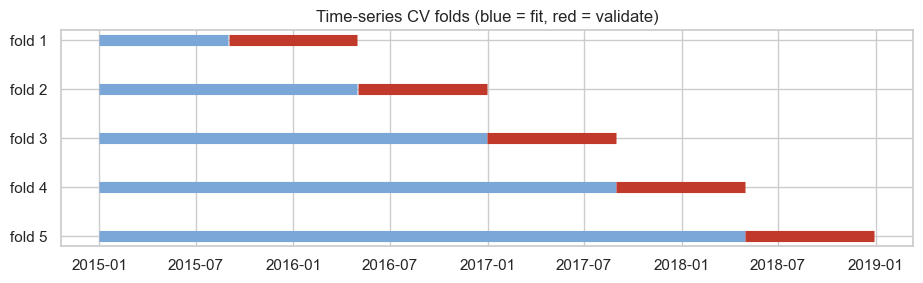

In [5]:
from src.train import time_folds
tr = feats[feats.split == "train"].sort_values(["Date", "City"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 2.8))
for k, (a, b) in enumerate(time_folds(tr["Date"])):
    ax.plot([tr.Date[a].min(), tr.Date[a].max()], [k, k], lw=8, c="#7aa6d8", solid_capstyle="butt")
    ax.plot([tr.Date[b].min(), tr.Date[b].max()], [k, k], lw=8, c="#c0392b", solid_capstyle="butt")
    assert tr.Date[a].max() < tr.Date[b].min()
ax.set_yticks(range(5), [f"fold {k+1}" for k in range(5)]); ax.invert_yaxis()
ax.set_title("Time-series CV folds (blue = fit, red = validate)"); plt.show()

## 4. Baselines (computed live)

* **Persistence**: tomorrow = today. Free, and very strong for an autocorrelated series.
* **Seasonal mean**: average of each (city, month) in the training data.

In [6]:
from src.train import Persistence, SeasonalMean
va = feats[feats.split == "val"]
X_cols = FEATURES + ["City"]
pers = Persistence().predict(va[X_cols])
seas = SeasonalMean().fit(tr[X_cols], tr.y.to_numpy()).predict(va[X_cols])
print(f"Validation 2019 MAE  persistence {mae(pers, va.y):.2f}   seasonal mean {mae(seas, va.y):.2f}")

Validation 2019 MAE  persistence 13.72   seasonal mean 28.03


**Insight:** knowing *yesterday* (MAE ≈ 13.7) beats knowing *the season* by a factor of two. Every model therefore has to be compared with persistence, not with a naive average.

## 5. Why the models predict the *change* from today

The ML models learn `y − pm_t` and add it back (`DeltaTarget` in `src/train.py`). The change is centred on 0 with a much narrower spread than the level, so the model only has to learn the correction to persistence. It also lets trees forecast values above anything seen in training.

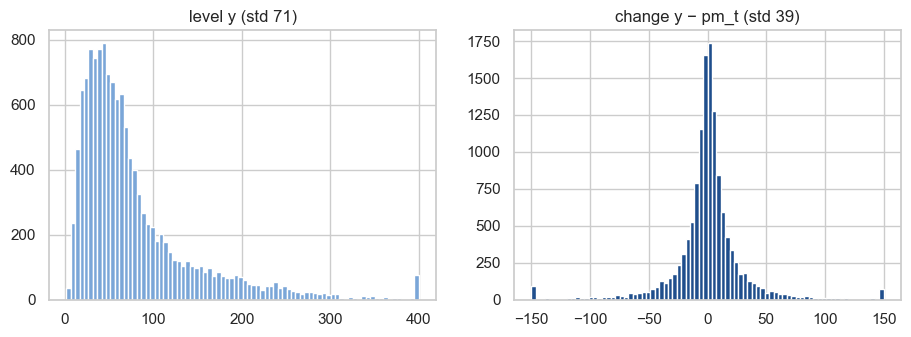

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(tr.y.clip(upper=400), bins=80, color="#7aa6d8"); ax[0].set_title(f"level y (std {tr.y.std():.0f})")
ax[1].hist((tr.y - tr.pm_t).clip(-150, 150), bins=80, color="#1f4e8c"); ax[1].set_title(f"change y − pm_t (std {(tr.y - tr.pm_t).std():.0f})")
plt.show()

## 6. Models and tuning results

| Model | Why | Search |
|---|---|---|
| Ridge | Linear and interpretable; tests whether a weighted sum of the features is enough | α over 13 values |
| Random forest | Non-linear, robust to outliers and collinear pollutants | 8 random draws |
| LightGBM | Boosting; usually best on tabular data, captures interactions like rain × season | 25 random draws, loss L2 / L1 / Huber |

Imputation, scaling and one-hot encoding sit inside each `Pipeline`, so they are re-fitted in every CV fold.

In [8]:
cv = pd.read_csv(TABLES / "cv_results.csv")
cv["cv"] = cv.cv_mean.round(3).astype(str) + " ± " + cv.cv_std.round(3).astype(str)
display(cv[["task", "model", "metric", "cv"]])
print(json.dumps(json.loads((TABLES / "best_params.json").read_text())["lightgbm"], indent=1))

,task,model,metric,cv
0,regression,persistence,MAE,21.533 ± 4.44
1,regression,seasonal_mean,MAE,39.783 ± 11.747
2,regression,ridge,MAE,20.823 ± 4.351
3,regression,random_forest,MAE,20.681 ± 4.491
4,regression,lightgbm,MAE,20.178 ± 4.544
5,classification,logistic,PR-AUC,0.904 ± 0.009
6,classification,lightgbm_clf,PR-AUC,0.922 ± 0.012


{
 "estimator__model__colsample_bytree": 0.7282672852414551,
 "estimator__model__learning_rate": 0.016536379754545756,
 "estimator__model__min_child_samples": 39,
 "estimator__model__num_leaves": 18,
 "estimator__model__objective": "l1",
 "estimator__model__reg_lambda": 0.0030785897480259308,
 "estimator__model__subsample": 0.7425191352307899,
 "estimator__model__subsample_freq": 1
}


**Insight:** the CV ranking is LightGBM < random forest < Ridge < persistence on MAE, but the fold-to-fold spread (±4.5) is larger than the gaps between models. That is why the final choice uses the 2019 validation year and why the report gives a bootstrap CI on test. Tuning picked the **L1 (MAE) loss** for LightGBM, matching the evaluation metric and making the model robust to the long right tail.

## 7. Re-checking the saved model

Load the LightGBM model trained on 2015–2018 and score it on 2019. The result must equal the number in `reports/tables/regression_results.csv`, which shows the saved model and the table agree.

In [9]:
lgbm = joblib.load(MODELS / "reg_lightgbm_trainonly.joblib")
val_mae = mae(lgbm.predict(va[FEATURES]), va.y)
table = pd.read_csv(TABLES / "regression_results.csv")
ref = table[(table.split == "val") & (table.model == "LightGBM")].MAE.iloc[0]
print(f"LightGBM val MAE recomputed {val_mae:.2f}  vs table {ref:.2f}")
assert abs(val_mae - ref) < 0.01

LightGBM val MAE recomputed 12.42  vs table 12.42


## 8. Demo: forecast for one city

The final model (refit on 2015–2019) forecasts Delhi's PM2.5 for **1 July 2020** from the data of 30 June, and also says whether that will be a Poor+ day.

In [10]:
final = joblib.load(MODELS / "reg_lightgbm.joblib")
thr = json.loads((TABLES / "thresholds.json").read_text())["lightgbm_reg_threshold"]
row = feats[feats.City == "Delhi"].sort_values("Date").tail(1)
pred = float(final.predict(row[FEATURES])[0])
print(f"Delhi {row.Date.iloc[0].date()}: today {row.pm_t.iloc[0]:.1f} µg/m³, rain today {row.precip_mm_t.iloc[0]:.1f} mm")
print(f"Forecast for {row.target_date.iloc[0].date()}: {pred:.1f} µg/m³ -> {'POOR+ warning' if pred > thr else 'no warning'} (threshold {thr:.1f})")
print(f"Actual: {row.y.iloc[0]:.1f} µg/m³   persistence would have said {row.pm_t.iloc[0]:.1f}")

Delhi 2020-06-30: today 39.8 µg/m³, rain today 2.1 mm
Forecast for 2020-07-01: 40.8 µg/m³ -> no warning (threshold 88.5)
Actual: 54.0 µg/m³   persistence would have said 39.8
